# Modèles 


## 0. Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from pathlib import Path
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

RANDOM_STATE = 42
N_ITER_XGB = 10        # nombre de combinaisons testées par la recherche
SHAP_SAMPLE = 1500     # lignes du test expliquées par SHAP

DATA_DIR = Path.cwd() / "data"
if not DATA_DIR.exists():
    DATA_DIR = Path.cwd().parent / "data"
PROCESSED = DATA_DIR / "processed"

## 1. Chargement

In [2]:
META = ["label", "attack_cat", "row_hash", "fold", "in_train", "is_duplicate"]


def load(name):
    """Sépare les features des métadonnées."""
    frame = pd.read_parquet(PROCESSED / f"{name}.parquet")
    features = frame.drop(columns=[c for c in META if c in frame.columns])
    meta = frame[[c for c in META if c in frame.columns]]
    return features, meta


X_train = {"linear": load("linear_train")[0], "trees": load("trees_train")[0]}
X_test = {"linear": load("linear_test")[0], "trees": load("trees_test")[0]}
train_meta = load("trees_train")[1]
test_meta = load("trees_test")[1]

y_train, y_test = train_meta["label"], test_meta["label"]
fold = train_meta["fold"].to_numpy()
mask_new = ~test_meta["in_train"].to_numpy().astype(bool)   
display(pd.DataFrame({
    "train": [len(y_train), X_train["linear"].shape[1], y_train.mean() * 100],
    "test": [len(y_test), X_test["linear"].shape[1], y_test.mean() * 100],
}, index=["lignes", "features (linéaire)", "% attaques"]).round(1))

,train,test
lignes,175341.0,82332.0
features (linéaire),49.0,49.0
% attaques,68.1,55.1


## 2. Modèles et métriques

In [3]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

MODELS = {
    "Régression logistique": ("linear", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "MLP": ("linear", MLPClassifier(
        hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=RANDOM_STATE)),
    "Random Forest": ("trees", RandomForestClassifier(
        n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
    "XGBoost": ("trees", XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=ratio, eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE)),
}


def predict_at(proba, threshold):
    return (np.asarray(proba) >= threshold).astype(int)


def metrics(y_true, proba, threshold=0.5):
    """Métriques binaires à un seuil donné."""
    y_true = np.asarray(y_true)
    pred = predict_at(proba, threshold)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "précision": precision_score(y_true, pred, zero_division=0),
        "rappel": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "pr_auc": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "fpr": fp / (fp + tn),
        "fnr": fn / (fn + tp),
    }

## 3. Validation croisée 

In [4]:
FOLD_IDS = sorted(np.unique(fold))
oof_proba, fold_rows = {}, []

for name, (kind, model) in MODELS.items():
    X = X_train[kind]
    oof = np.full(len(y_train), np.nan)
    for k in FOLD_IDS:
        tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
        est = clone(model).fit(X.iloc[tr], y_train.iloc[tr])
        oof[va] = est.predict_proba(X.iloc[va])[:, 1]
        fold_rows.append({"modèle": name, "fold": int(k), **metrics(y_train.iloc[va], oof[va])})
    oof_proba[name] = oof

cv_folds = pd.DataFrame(fold_rows)
cv_results = cv_folds.groupby("modèle").agg(
    f1=("f1", "mean"), f1_std=("f1", "std"), précision=("précision", "mean"),
    rappel=("rappel", "mean"), pr_auc=("pr_auc", "mean"), roc_auc=("roc_auc", "mean"),
    fpr=("fpr", "mean"), fnr=("fnr", "mean"),
).reindex(list(MODELS))
display(cv_results.round(4))

,f1,f1_std,précision,rappel,pr_auc,roc_auc,fpr,fnr
modèle,,,,,,,,
Régression logistique,0.9503,0.0021,0.9529,0.9477,0.9913,0.9826,0.0998,0.0523
MLP,0.9615,0.0012,0.9524,0.9708,0.9954,0.9906,0.1034,0.0292
Random Forest,0.9645,0.0017,0.9695,0.9595,0.9957,0.9917,0.0642,0.0405
XGBoost,0.9636,0.0014,0.9766,0.9510,0.9968,0.9933,0.0485,0.0490


## 4. Seuil de décision 

In [5]:
def choose_thresholds(y_true, proba):
    precision, recall, thr = precision_recall_curve(y_true, proba)
    f1_curve = 2 * precision * recall / (precision + recall + 1e-12)
    seuil_f1 = float(thr[np.nanargmax(f1_curve[:-1])])
    ok = np.where(recall[:-1] >= 0.95)[0]
    seuil_r95 = float(thr[ok[np.argmax(precision[:-1][ok])]]) if len(ok) else 0.0
    return seuil_f1, seuil_r95


thresholds = pd.DataFrame(
    {name: choose_thresholds(y_train, p) for name, p in oof_proba.items()},
    index=["seuil_f1", "seuil_rappel95"],
).T
display(thresholds.round(4))

,seuil_f1,seuil_rappel95
Régression logistique,0.3214,0.4923
MLP,0.4311,0.6233
Random Forest,0.3817,0.5567
XGBoost,0.3153,0.5059


## 5. Évaluation sur le test officiel

In [6]:
fitted, test_proba, rows = {}, {}, {}

for name, (kind, model) in MODELS.items():
    fitted[name] = clone(model).fit(X_train[kind], y_train)
    p = fitted[name].predict_proba(X_test[kind])[:, 1]
    test_proba[name] = p
    rows[(name, "seuil 0,5")] = metrics(y_test, p, 0.5)
    rows[(name, "seuil F1 (OOF)")] = metrics(y_test, p, thresholds.loc[name, "seuil_f1"])
    rows[(name, "seuil rappel 95 % (OOF)")] = metrics(y_test, p, thresholds.loc[name, "seuil_rappel95"])
    rows[(name, "seuil 0,5, sans lignes vues")] = metrics(y_test.to_numpy()[mask_new], p[mask_new], 0.5)

test_results = pd.DataFrame(rows).T
display(test_results.round(4))

précision  rappel      f1  \
Régression logistique seuil 0,5                       0.8164  0.9254  0.8675   
                      seuil F1 (OOF)                  0.7601  0.9635  0.8498   
                      seuil rappel 95 % (OOF)         0.8132  0.9278  0.8668   
                      seuil 0,5, sans lignes vues     0.8102  0.9201  0.8616   
MLP                   seuil 0,5                       0.8002  0.9815  0.8816   
                      seuil F1 (OOF)                  0.7811  0.9886  0.8727   
                      seuil rappel 95 % (OOF)         0.8415  0.9656  0.8993   
                      seuil 0,5, sans lignes vues     0.7930  0.9802  0.8767   
Random Forest         seuil 0,5                       0.8541  0.9752  0.9107   
                      seuil F1 (OOF)                  0.8137  0.9889  0.8928   
                      seuil rappel 95 % (OOF)         0.8738  0.9664  0.9177   
                      seuil 0,5, sans lignes vues     0.8468  0.9736  0.9058   
XGBoost               seuil 0,5                       0.8742  0.9652  0.9175   
                      seuil F1 (OOF)                  0.8164  0.9872  0.8937   
                      seuil rappel 95 % (OOF)         0.8763  0.9644  0.9182   
                      seuil 0,5, sans lignes vues     0.8700  0.9627  0.9140   

                                                   pr_auc  roc_auc     fpr  \
Régression logistique seuil 0,5                    0.9664   0.9544  0.2550   
                      seuil F1 (OOF)               0.9664   0.9544  0.3725   
                      seuil rappel 95 % (OOF)      0.9664   0.9544  0.2611   
                      seuil 0,5, sans lignes vues  0.9636   0.9519  0.2546   
MLP                   seuil 0,5                    0.9837   0.9779  0.3002   
                      seuil F1 (OOF)               0.9837   0.9779  0.3395   
                      seuil rappel 95 % (OOF)      0.9837   0.9779  0.2229   
                      seuil 0,5, sans lignes vues  0.9818   0.9762  0.3020   
Random Forest         seuil 0,5                    0.9864   0.9824  0.2041   
                      seuil F1 (OOF)               0.9864   0.9824  0.2775   
                      seuil rappel 95 % (OOF)      0.9864   0.9824  0.1710   
                      seuil 0,5, sans lignes vues  0.9846   0.9808  0.2079   
XGBoost               seuil 0,5                    0.9883   0.9841  0.1701   
                      seuil F1 (OOF)               0.9883   0.9841  0.2720   
                      seuil rappel 95 % (OOF)      0.9883   0.9841  0.1669   
                      seuil 0,5, sans lignes vues  0.9869   0.9828  0.1699   

                                                      fnr  
Régression logistique seuil 0,5                    0.0746  
                      seuil F1 (OOF)               0.0365  
                      seuil rappel 95 % (OOF)      0.0722  
                      seuil 0,5, sans lignes vues  0.0799  
MLP                   seuil 0,5                    0.0185  
                      seuil F1 (OOF)               0.0114  
                      seuil rappel 95 % (OOF)      0.0344  
                      seuil 0,5, sans lignes vues  0.0198  
Random Forest         seuil 0,5                    0.0248  
                      seuil F1 (OOF)               0.0111  
                      seuil rappel 95 % (OOF)      0.0336  
                      seuil 0,5, sans lignes vues  0.0264  
XGBoost               seuil 0,5                    0.0348  
                      seuil F1 (OOF)               0.0128  
                      seuil rappel 95 % (OOF)      0.0356  
                      seuil 0,5, sans lignes vues  0.0373

## 6. Matrices de confusion et courbes

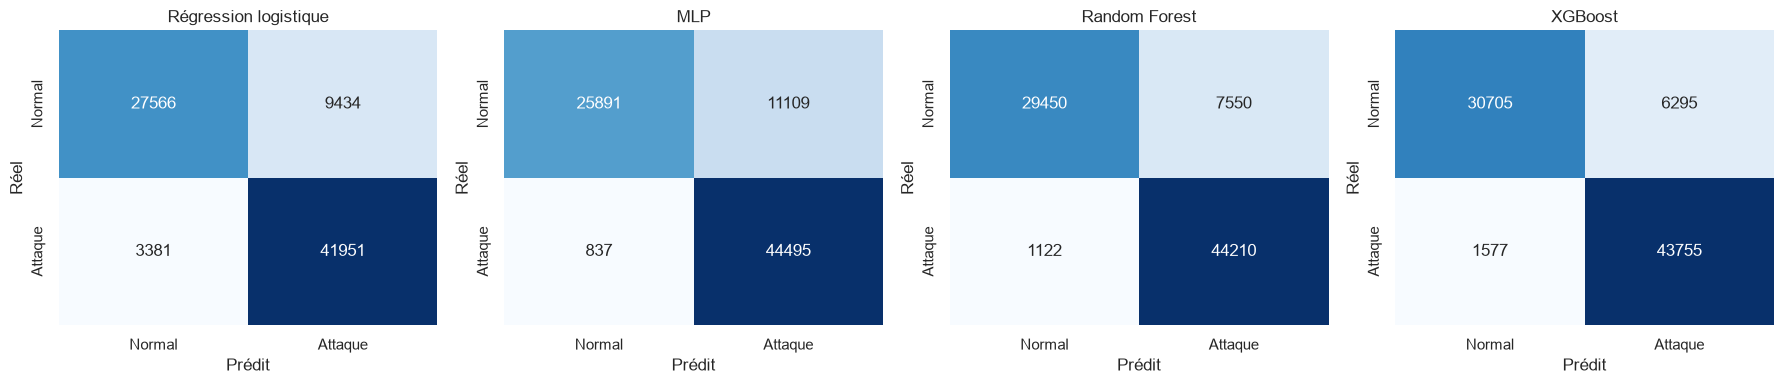

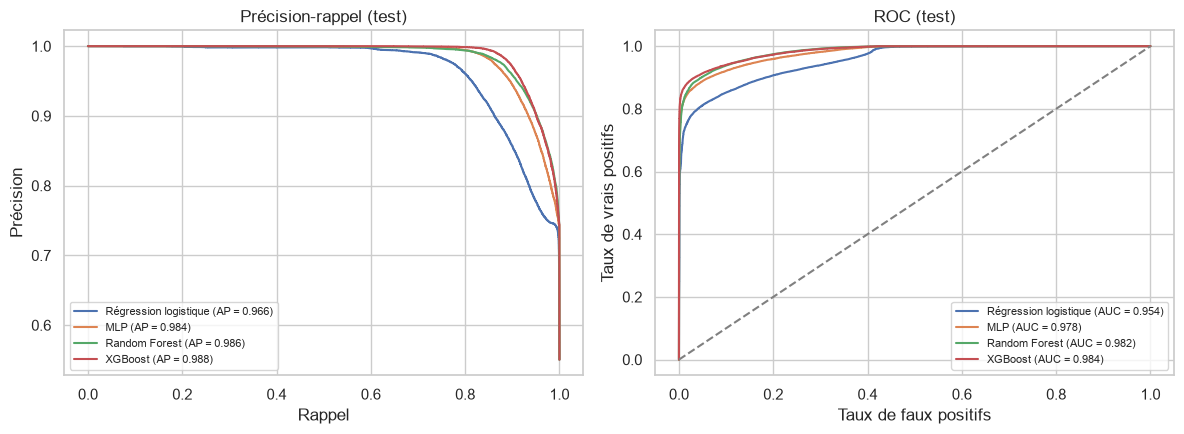

In [7]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.5 * len(MODELS), 4))
for ax, (name, p) in zip(axes, test_proba.items()):
    sns.heatmap(confusion_matrix(y_test, predict_at(p, 0.5)), annot=True, fmt="d", cmap="Blues",
                cbar=False, ax=ax, xticklabels=["Normal", "Attaque"], yticklabels=["Normal", "Attaque"])
    ax.set_title(name); ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, p in test_proba.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rc, pr, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
    fp_, tp_, _ = roc_curve(y_test, p)
    axes[1].plot(fp_, tp_, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[0].set(xlabel="Rappel", ylabel="Précision", title="Précision-rappel (test)")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set(xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs", title="ROC (test)")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Optimisation des hyperparamètres (XGBoost)


In [8]:
param_dist = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.03, 0.05, 0.08, 0.1, 0.15],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0.0, 0.1, 0.3, 0.5],
    "reg_lambda": [0.5, 1.0, 2.0, 5.0],
}
search = RandomizedSearchCV(
    clone(MODELS["XGBoost"][1]), param_dist, n_iter=N_ITER_XGB,
    scoring={"f1": "f1", "pr_auc": "average_precision"}, refit="pr_auc",
    cv=PredefinedSplit(fold), n_jobs=1, random_state=RANDOM_STATE,
)
search.fit(X_train["trees"], y_train)

res = pd.DataFrame(search.cv_results_)
display(res[["rank_test_pr_auc", "mean_test_pr_auc", "mean_test_f1", "params"]]
        .sort_values("rank_test_pr_auc").head(5).round(4))
print("Meilleurs paramètres :", search.best_params_)

tuned_xgb = search.best_estimator_
tuned_proba = tuned_xgb.predict_proba(X_test["trees"])[:, 1]
default_proba = test_proba["XGBoost"]

comparison = pd.DataFrame({
    "XGBoost par défaut": [cv_results.loc["XGBoost", "pr_auc"], cv_results.loc["XGBoost", "f1"],
                           *[metrics(y_test, default_proba)[m] for m in ("pr_auc", "f1")]],
    "XGBoost optimisé": [search.best_score_, res.loc[search.best_index_, "mean_test_f1"],
                         *[metrics(y_test, tuned_proba)[m] for m in ("pr_auc", "f1")]],
}, index=["PR-AUC CV", "F1 CV", "PR-AUC test", "F1 test (0,5)"])
display(comparison.round(4))

,rank_test_pr_auc,mean_test_pr_auc,mean_test_f1,params
7,1,0.9969,0.9651,"{'subsample': 0.9, 'reg_lambda': 1.0, 'n_estim..."
8,2,0.9968,0.9654,"{'subsample': 0.8, 'reg_lambda': 2.0, 'n_estim..."
4,3,0.9966,0.9613,"{'subsample': 1.0, 'reg_lambda': 1.0, 'n_estim..."
9,4,0.9966,0.9609,"{'subsample': 0.9, 'reg_lambda': 0.5, 'n_estim..."
1,5,0.9965,0.9605,"{'subsample': 1.0, 'reg_lambda': 0.5, 'n_estim..."


Meilleurs paramètres : {'subsample': 0.9, 'reg_lambda': 1.0, 'n_estimators': 400, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.08, 'gamma': 0.0, 'colsample_bytree': 0.8}


,XGBoost par défaut,XGBoost optimisé
PR-AUC CV,0.9968,0.9969
F1 CV,0.9636,0.9651
PR-AUC test,0.9883,0.9882
"F1 test (0,5)",0.9175,0.9160


## 8. Explicabilité


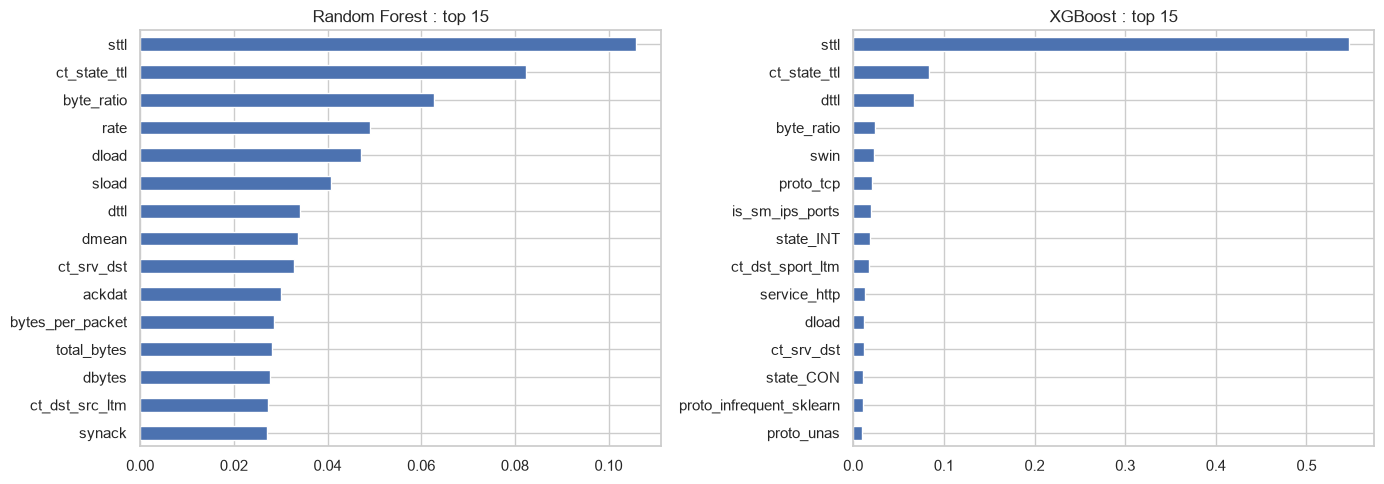

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    imp = pd.Series(fitted[name].feature_importances_, index=X_train["trees"].columns)
    imp.nlargest(15).sort_values().plot.barh(ax=ax)
    ax.set_title(f"{name} : top 15")
plt.tight_layout(); plt.show()

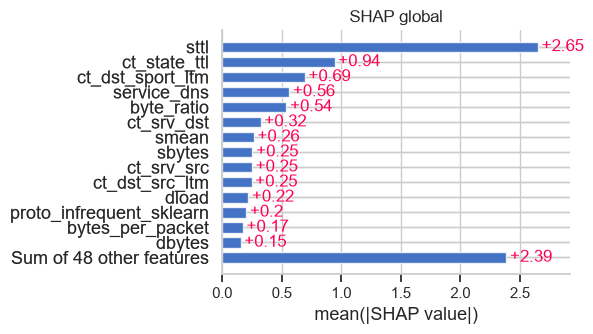

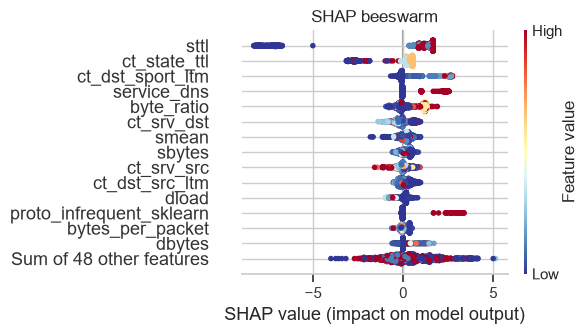

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(X_test["trees"]), size=min(SHAP_SAMPLE, len(X_test["trees"])), replace=False)
shap_X = X_test["trees"].iloc[idx].reset_index(drop=True)
explainer = shap.TreeExplainer(tuned_xgb)
shap_values = explainer(shap_X)

shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("SHAP global (XGBoost optimisé)"); plt.tight_layout(); plt.show()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP beeswarm"); plt.tight_layout(); plt.show()

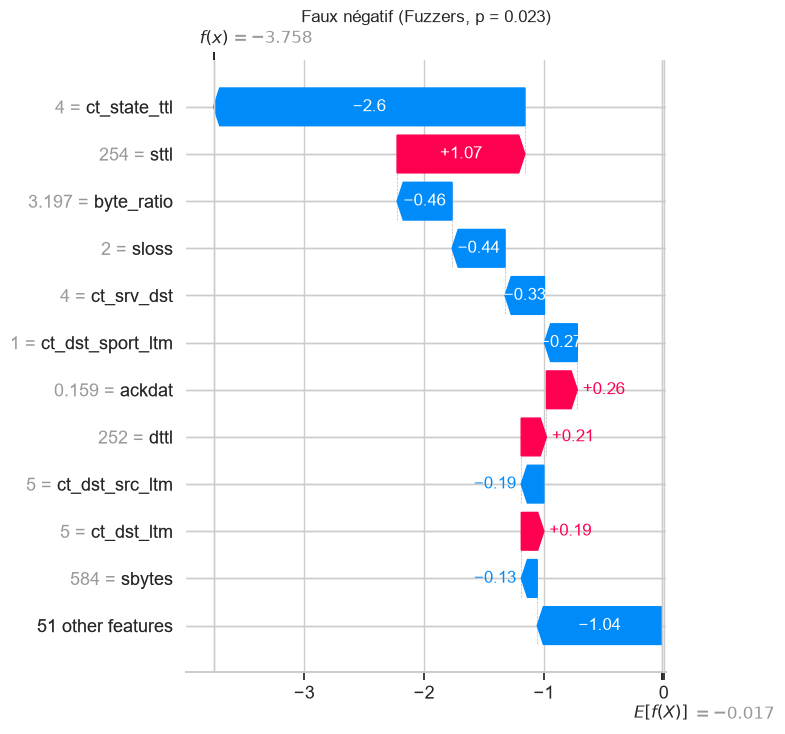

In [ ]:

pred_tuned = predict_at(tuned_proba, 0.5)
y_arr = y_test.to_numpy()
fn_idx = np.where((y_arr == 1) & (pred_tuned == 0))[0]
i = int(fn_idx[np.argmin(tuned_proba[fn_idx])])

shap.plots.waterfall(explainer(X_test["trees"].iloc[[i]])[0], max_display=12, show=False)
plt.title(f"Faux négatif ({test_meta['attack_cat'].iloc[i]}, p = {tuned_proba[i]:.3f})")
plt.tight_layout(); plt.show()

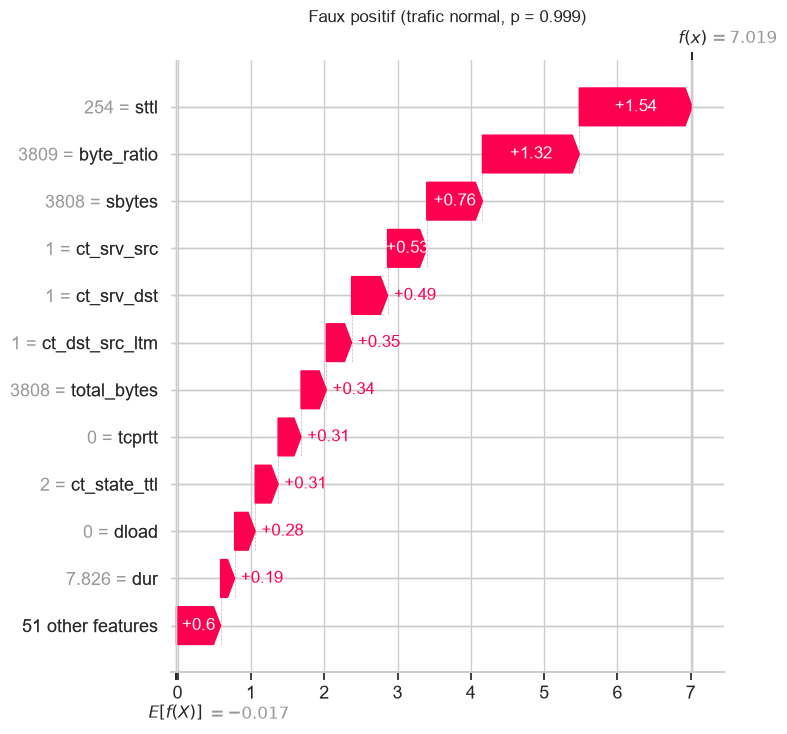

In [12]:
# Explication locale : le faux positif le plus « sûr » de lui (probabilité la plus haute)
fp_idx = np.where((y_arr == 0) & (pred_tuned == 1))[0]
j = int(fp_idx[np.argmax(tuned_proba[fp_idx])])

shap.plots.waterfall(explainer(X_test["trees"].iloc[[j]])[0], max_display=12, show=False)
plt.title(f"Faux positif (trafic normal, p = {tuned_proba[j]:.3f})")
plt.tight_layout(); plt.show()

## 9. Analyse d'erreurs

,support,FN Régression logistique,Régression logistique,FN MLP,MLP,FN Random Forest,Random Forest,FN XGBoost,XGBoost
Generic,18871,77,0.996,4,1.000,1,1.000,2,1.000
Exploits,11132,960,0.914,50,0.996,82,0.993,99,0.991
Fuzzers,6062,1963,0.676,756,0.875,1014,0.833,1414,0.767
DoS,4089,183,0.955,13,0.997,10,0.998,12,0.997
Reconnaissance,3496,90,0.974,7,0.998,5,0.999,6,0.998
Analysis,677,58,0.914,1,0.999,4,0.994,35,0.948
Backdoor,583,12,0.979,1,0.998,1,0.998,1,0.998
Shellcode,378,33,0.913,5,0.987,5,0.987,7,0.981
Worms,44,5,0.886,0,1.000,0,1.000,1,0.977


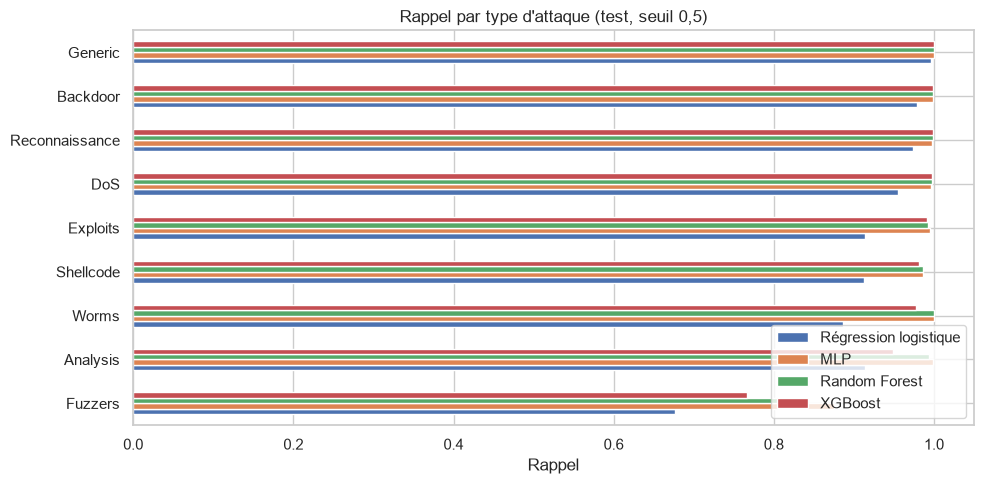

In [ ]:
atk = y_arr == 1
cats = test_meta["attack_cat"].to_numpy()[atk]
table = pd.DataFrame({"support": pd.Series(cats).value_counts()})
for name, p in test_proba.items():
    miss = pd.Series(predict_at(p, 0.5)[atk] == 0).groupby(cats).sum()
    table[f"FN {name}"] = miss
    table[name] = 1 - miss / table["support"]
rappel_cols = list(MODELS)
display(table.sort_values("support", ascending=False).round(3))

table.loc[:, rappel_cols].sort_values("XGBoost").plot.barh(figsize=(10, 5))
plt.xlabel("Rappel"); plt.title("Rappel par type d'attaque (test, seuil 0,5)")
plt.tight_layout(); plt.show()

In [ ]:
outcome = np.select(
    [(y_arr == 0) & (pred_tuned == 0), (y_arr == 0) & (pred_tuned == 1),
     (y_arr == 1) & (pred_tuned == 0), (y_arr == 1) & (pred_tuned == 1)],
    ["TN", "FP", "FN", "TP"], default="TN")
cols = ["sttl", "ct_state_ttl", "dur", "rate", "sload"]
profile = X_test["trees"][cols].assign(outcome=outcome).groupby("outcome")[cols].median()
profile.insert(0, "n", pd.Series(outcome).value_counts())
display(profile.reindex(["TN", "FP", "FN", "TP"]).round(3))

seen = ~mask_new
display(pd.DataFrame({
    "lignes vues": metrics(y_arr[seen], tuned_proba[seen]),
    "lignes non vues": metrics(y_arr[mask_new], tuned_proba[mask_new]),
}).T.round(4))

,n,sttl,ct_state_ttl,dur,rate,sload
outcome,,,,,,
TN,30259,31.0,0.0,0.128,233.128,1.708783e+05
FP,6741,254.0,1.0,0.661,29.203,1.223249e+04
FN,1329,254.0,1.0,0.537,32.897,1.163521e+04
TP,44003,254.0,2.0,0.000,111111.107,5.066666e+07


,précision,rappel,f1,pr_auc,roc_auc,fpr,fnr
lignes vues,0.9382,0.9993,0.9678,0.9999,0.9996,0.1685,0.0007
lignes non vues,0.8623,0.9686,0.9124,0.9868,0.9827,0.1826,0.0314


## 10. Contrôle : entraînement sans doublons



In [15]:
unique_idx = np.where((~train_meta["row_hash"].duplicated()).to_numpy())[0]
X_dedup = {kind: X_train[kind].iloc[unique_idx].reset_index(drop=True) for kind in X_train}
y_dedup = y_train.iloc[unique_idx].reset_index(drop=True)

assert len(y_dedup) == 107740
assert all(len(X_dedup[kind]) == len(y_dedup) for kind in X_train)

dedup_rows = {}
for name, (kind, model) in MODELS.items():
    estimator = clone(model).fit(X_dedup[kind], y_dedup)
    proba = estimator.predict_proba(X_test[kind])[:, 1]
    dedup_rows[name] = metrics(y_test, proba, 0.5)

dedup_results = pd.DataFrame(dedup_rows).T
full_05 = test_results.xs("seuil 0,5", level=1)

dedup_comparison = pd.DataFrame({
    "F1 train complet": full_05["f1"],
    "F1 train dédupliqué": dedup_results["f1"],
    "Δ F1": dedup_results["f1"] - full_05["f1"],
    "Δ PR-AUC": dedup_results["pr_auc"] - full_05["pr_auc"],
})
display(dedup_comparison.round(4))

,F1 train complet,F1 train dédupliqué,Δ F1,Δ PR-AUC
Régression logistique,0.8675,0.8493,-0.0182,-0.0033
MLP,0.8816,0.8929,0.0113,0.0005
Random Forest,0.9107,0.8983,-0.0124,-0.0008
XGBoost,0.9175,0.9182,0.0007,-0.0001


## 11. Ablation des artefacts 

In [16]:
ART = ["sttl", "ct_state_ttl"]
Xa, Xa_test = X_train["trees"].drop(columns=ART), X_test["trees"].drop(columns=ART)

oof_a = np.full(len(y_train), np.nan)
for k in FOLD_IDS:
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    oof_a[va] = clone(tuned_xgb).fit(Xa.iloc[tr], y_train.iloc[tr]).predict_proba(Xa.iloc[va])[:, 1]

proba_a = clone(tuned_xgb).fit(Xa, y_train).predict_proba(Xa_test)[:, 1]

display(pd.DataFrame({
    "XGBoost complet": [average_precision_score(y_train, oof_a * 0 + search.best_estimator_.predict_proba(X_train["trees"])[:, 1]) if False else search.best_score_,
                        metrics(y_test, tuned_proba)["pr_auc"], metrics(y_test, tuned_proba)["f1"]],
    "sans sttl / ct_state_ttl": [average_precision_score(y_train, oof_a),
                                 metrics(y_test, proba_a)["pr_auc"], metrics(y_test, proba_a)["f1"]],
}, index=["PR-AUC CV", "PR-AUC test", "F1 test (0,5)"]).round(4))

,XGBoost complet,sans sttl / ct_state_ttl
PR-AUC CV,0.9969,0.9969
PR-AUC test,0.9882,0.9875
"F1 test (0,5)",0.9160,0.9141


## 12. Synthèse

In [17]:
summary = pd.DataFrame({
    "F1 CV": cv_results["f1"],
    "PR-AUC CV": cv_results["pr_auc"],
    "F1 test (0,5)": test_results.xs("seuil 0,5", level=1)["f1"],
    "PR-AUC test": test_results.xs("seuil 0,5", level=1)["pr_auc"],
    "FNR test": test_results.xs("seuil 0,5", level=1)["fnr"],
    "FPR test": test_results.xs("seuil 0,5", level=1)["fpr"],
})
summary.loc["XGBoost optimisé"] = [res.loc[search.best_index_, "mean_test_f1"],
                                   search.best_score_, *[metrics(y_test, tuned_proba)[m] for m in ("f1", "pr_auc", "fnr", "fpr")]]
display(summary.sort_values("PR-AUC CV", ascending=False).round(4))

,F1 CV,PR-AUC CV,"F1 test (0,5)",PR-AUC test,FNR test,FPR test
XGBoost optimisé,0.9651,0.9969,0.9160,0.9882,0.0293,0.1822
XGBoost,0.9636,0.9968,0.9175,0.9883,0.0348,0.1701
Random Forest,0.9645,0.9957,0.9107,0.9864,0.0248,0.2041
MLP,0.9615,0.9954,0.8816,0.9837,0.0185,0.3002
Régression logistique,0.9503,0.9913,0.8675,0.9664,0.0746,0.2550
